In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt

########################################
# 1. Hyperparameters & Setup
########################################
num_epochs = 50
batch_size = 1024
learning_rate = 0.01

alphas = [0.01, 0.0001, 0.000001, 0.0]   # The three alpha values to try
redundancy_freq = 5       # How often to compute the redundancy loss

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

########################################
# 2. CIFAR-10 Dataset
########################################
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),  # CIFAR-10 mean
                         (0.2023, 0.1994, 0.2010))  # CIFAR-10 std
])

train_dataset = torchvision.datasets.CIFAR10(root='./data',
                                             train=True,
                                             download=True,
                                             transform=transform)
train_loader = torch.utils.data.DataLoader(train_dataset,
                                           batch_size=batch_size,
                                           shuffle=True,
                                           num_workers=2)

test_dataset = torchvision.datasets.CIFAR10(root='./data',
                                            train=False,
                                            download=True,
                                            transform=transform)
test_loader = torch.utils.data.DataLoader(test_dataset,
                                          batch_size=batch_size,
                                          shuffle=False,
                                          num_workers=2)

########################################
# 3. Define a Smaller MLP
########################################
class SmallMLP(nn.Module):
    """
    A smaller MLP:
      Input (3072) -> FC1(128) -> ReLU -> FC2(64) -> ReLU -> FC3(10)
    """
    def __init__(self):
        super(SmallMLP, self).__init__()
        self.fc1 = nn.Linear(3*32*32, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)

        self.relu = nn.ReLU()

    def forward(self, x, collect_inputs=False):
        """
        If collect_inputs=True, we'll return the input activations
        for each layer (so we can compute S for L_red).
        """
        # Flatten input
        x = x.view(x.size(0), -1)
        if collect_inputs:
            inputs_list = [x]  # input to fc1

        x = self.fc1(x)
        x = self.relu(x)
        if collect_inputs:
            inputs_list.append(x)  # input to fc2

        x = self.fc2(x)
        x = self.relu(x)
        if collect_inputs:
            inputs_list.append(x)  # input to fc3

        x = self.fc3(x)
        if collect_inputs:
            return x, inputs_list
        else:
            return x

########################################
# 4. Redundancy Functions
########################################
def covariance_matrix(batch_activations):
    """
    Compute empirical covariance: (X - mean(X))^T (X - mean(X)) / (N - 1)
    batch_activations: shape [batch_size, d]
    """
    X = batch_activations - batch_activations.mean(dim=0, keepdim=True)
    N = X.shape[0]
    if N > 1:
        return (X.t() @ X) / (N - 1)
    else:
        return torch.zeros(X.shape[1], X.shape[1], device=X.device)

def layer_redundancy_loss(weight_matrix, cov_matrix):
    """
    Average of pairwise correlations among neurons:
      (1 / #pairs) * sum_{i<j} (w_i^T S w_j)/(||w_i|| ||w_j||)
    weight_matrix: shape [out_features, in_features]
    cov_matrix   : shape [in_features, in_features]
    """
    out_features = weight_matrix.shape[0]
    W = weight_matrix.float()
    layer_loss = 0.0

    # Count how many pairs we have, i < j
    # out_features * (out_features - 1) / 2
    num_pairs = out_features * (out_features - 1) // 2
    if num_pairs == 0:
        return torch.tensor(0.0, device=weight_matrix.device)

    for i in range(out_features):
        w_i = W[i]
        norm_i = torch.norm(w_i) + 1e-8
        for j in range(i+1, out_features):
            w_j = W[j]
            norm_j = torch.norm(w_j) + 1e-8
            corr_ij = (w_i @ cov_matrix @ w_j) / (norm_i * norm_j)
            layer_loss += torch.abs(corr_ij)

    # Average by the number of pairs
    layer_loss = layer_loss / num_pairs
    return layer_loss

def redundancy_loss(model, layer_inputs):
    """
    Compute L_red across all layers:
      layer_inputs: [input to fc1, input to fc2, input to fc3]
    """
    total_loss = 0.0

    # Cov for input to fc1, w for fc1
    S1 = covariance_matrix(layer_inputs[0])
    w1 = model.fc1.weight  # shape [128, 3072]
    total_loss += layer_redundancy_loss(w1, S1)

    # Cov for input to fc2, w for fc2
    S2 = covariance_matrix(layer_inputs[1])
    w2 = model.fc2.weight  # shape [64, 128]
    total_loss += layer_redundancy_loss(w2, S2)

    # Cov for input to fc3, w for fc3
    S3 = covariance_matrix(layer_inputs[2])
    w3 = model.fc3.weight  # shape [10, 64]
    total_loss += layer_redundancy_loss(w3, S3)

    return total_loss

########################################
# 5. Training Function
########################################
def train_model(alpha, redundancy_freq):
    """
    Train the model using cross-entropy + alpha * L_red,
    but only compute L_red every `redundancy_freq` steps to reduce overhead.
    """
    model = SmallMLP().to(device)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.CrossEntropyLoss()

    train_losses = []
    test_accuracies = []

    step = 0
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            # Forward pass
            if step % redundancy_freq == 0:
                # We'll collect inputs for computing L_red
                outputs, layer_inps = model(images, collect_inputs=True)
                # Compute L_red only this step
                L_red = redundancy_loss(model, layer_inps)
            else:
                outputs = model(images, collect_inputs=False)
                L_red = 0.0

            L0 = criterion(outputs, labels)
            loss = L0 + alpha * L_red

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            step += 1

        avg_loss = running_loss / len(train_loader.dataset)
        train_losses.append(avg_loss)

        # Evaluate on the test set
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
        accuracy = 100.0 * correct / total
        test_accuracies.append(accuracy)

        print(f"[Epoch {epoch+1}/{num_epochs}] alpha={alpha} "
              f"Train Loss: {avg_loss:.4f} | Test Acc: {accuracy:.2f}%")

    return model, train_losses, test_accuracies

########################################
# 6. Run Experiments for 3 Alpha Values
########################################
results = {}
for alpha_val in alphas:
    print(f"\n======== Training with alpha={alpha_val} ========")
    trained_model, tr_losses, te_accs = train_model(alpha_val, redundancy_freq)
    results[alpha_val] = {
        "model": trained_model,
        "train_losses": tr_losses,
        "test_accuracies": te_accs
    }

########################################
# 7. Plot Loss & Accuracy Comparisons
########################################
fig, axs = plt.subplots(1,2, figsize=(12,5))
for alpha_val in alphas:
    axs[0].plot(results[alpha_val]["train_losses"], label=f"alpha={alpha_val}")
axs[0].set_title("Training Loss vs Epoch")
axs[0].set_xlabel("Epoch")
axs[0].set_ylabel("Loss")
axs[0].legend()

for alpha_val in alphas:
    axs[1].plot(results[alpha_val]["test_accuracies"], label=f"alpha={alpha_val}")
axs[1].set_title("Test Accuracy vs Epoch")
axs[1].set_xlabel("Epoch")
axs[1].set_ylabel("Accuracy (%)")
axs[1].legend()

plt.show()

################################################################################
# 8. Compute "RQ" Values for Each Node: (w_i^T S w_i) / ||w_i||^2
################################################################################
@torch.no_grad()
def compute_layer_input_covariances(model, data_loader):
    """
    Pass the entire dataset (via data_loader) through the model, collecting the
    *input activations* for each layer. Then compute the covariance of each layer's input.
    
    Returns a dict:
      {
        "fc1": (covariance of input to fc1),
        "fc2": (covariance of input to fc2),
        "fc3": (covariance of input to fc3)
      }
    """
    model.eval()
    layer_inputs_accum = {
        "fc1": [],
        "fc2": [],
        "fc3": []
    }

    for images, _ in data_loader:
        images = images.to(device)
        # We want the input to fc1, fc2, fc3
        # So do a forward pass with collect_inputs=True
        _, layer_inps = model(images, collect_inputs=True)
        # layer_inps = [input_to_fc1, input_to_fc2, input_to_fc3]
        layer_inputs_accum["fc1"].append(layer_inps[0].cpu())
        layer_inputs_accum["fc2"].append(layer_inps[1].cpu())
        layer_inputs_accum["fc3"].append(layer_inps[2].cpu())

    # Concatenate over the batch dimension
    covs = {}
    for layer_name in ["fc1", "fc2", "fc3"]:
        big_input = torch.cat(layer_inputs_accum[layer_name], dim=0)  # shape [N, in_features]
        covs[layer_name] = covariance_matrix(big_input)
    return covs

@torch.no_grad()
def compute_node_RQs(model, data_loader):
    """
    For each layer l in [fc1, fc2, fc3], and each neuron i in that layer,
    compute the Rayleigh quotient:
        RQ_i = (w_i^T S_l w_i) / (w_i^T w_i),
    where S_l is the covariance of the *input* to layer l.

    Returns a dict of lists:
      {
        "fc1": [RQ_1, RQ_2, ..., RQ_out_features],
        "fc2": [...],
        "fc3": [...]
      }
    """
    model.eval()

    # 1) Get covariance of each layer's input (on CPU or GPU as you prefer)
    covs = compute_layer_input_covariances(model, data_loader)
    # e.g., covs["fc1"], covs["fc2"], covs["fc3"]

    # 2) Move the layer weights to the same device as covs
    #    If covs are on CPU, do .cpu(); if covs are on CUDA, do .to(device).
    w_fc1 = model.fc1.weight.data.float().cpu()
    w_fc2 = model.fc2.weight.data.float().cpu()
    w_fc3 = model.fc3.weight.data.float().cpu()

    RQs = {"fc1": [], "fc2": [], "fc3": []}

    # fc1
    for w_i in w_fc1:
        RQ_i = node_rayleigh_quotient(w_i, covs["fc1"])
        RQs["fc1"].append(RQ_i.item())

    # fc2
    for w_i in w_fc2:
        RQ_i = node_rayleigh_quotient(w_i, covs["fc2"])
        RQs["fc2"].append(RQ_i.item())

    # fc3
    for w_i in w_fc3:
        RQ_i = node_rayleigh_quotient(w_i, covs["fc3"])
        RQs["fc3"].append(RQ_i.item())

    return RQs


def node_rayleigh_quotient(w_i, S, eps=1e-8):
    top = w_i @ S @ w_i
    bottom = w_i @ w_i + eps
    return top / bottom


################################################################################
# 9. Plot RQ Distributions per Layer for Each alpha
################################################################################
# We'll compute RQs for each alpha's trained model, then
# plot them side by side.

layer_names = ["fc1", "fc2", "fc3"]
# We'll store RQs as RQs_by_alpha[ alpha_val ][ layer_name ] = list_of_RQs
RQs_by_alpha = {}

for alpha_val in alphas:
    print(f"\nCompute RQs for alpha={alpha_val}")
    model = results[alpha_val]["model"]
    RQs = compute_node_RQs(model, train_loader)  # or test_loader
    RQs_by_alpha[alpha_val] = RQs

# Let's produce one figure with one subplot per layer
# and overlay the RQ distributions for alpha=0, 0.5, 1.0
fig, axes = plt.subplots(1, len(layer_names), figsize=(15,5), sharey=True)
bins = 30

for idx, layer_name in enumerate(layer_names):
    ax = axes[idx]
    for alpha_val in alphas:
        ax.hist(RQs_by_alpha[alpha_val][layer_name],
                bins=bins,
                alpha=0.4,
                label=f"alpha={alpha_val}")
    ax.set_title(f"Layer {layer_name} RQ Distribution")
    ax.set_xlabel("RQ = (w_i^T S w_i) / ||w_i||^2")
    if idx == 0:
        ax.set_ylabel("Count")
    ax.legend()

plt.tight_layout()
plt.show()

Using device: cuda
Files already downloaded and verified
Files already downloaded and verified

======== Training with alpha=0.01 ========
[Epoch 1/50] alpha=0.01 Train Loss: 2.8057 | Test Acc: 39.60%
[Epoch 2/50] alpha=0.01 Train Loss: 1.6796 | Test Acc: 43.32%
[Epoch 3/50] alpha=0.01 Train Loss: 1.5385 | Test Acc: 47.10%
[Epoch 4/50] alpha=0.01 Train Loss: 1.4629 | Test Acc: 46.56%
[Epoch 5/50] alpha=0.01 Train Loss: 1.4046 | Test Acc: 48.44%
[Epoch 6/50] alpha=0.01 Train Loss: 1.3596 | Test Acc: 48.94%
[Epoch 7/50] alpha=0.01 Train Loss: 1.3201 | Test Acc: 48.98%
[Epoch 8/50] alpha=0.01 Train Loss: 1.2834 | Test Acc: 49.96%
[Epoch 9/50] alpha=0.01 Train Loss: 1.2518 | Test Acc: 49.04%
[Epoch 10/50] alpha=0.01 Train Loss: 1.2249 | Test Acc: 49.43%
[Epoch 11/50] alpha=0.01 Train Loss: 1.2023 | Test Acc: 49.58%
[Epoch 12/50] alpha=0.01 Train Loss: 1.2075 | Test Acc: 49.08%
[Epoch 13/50] alpha=0.01 Train Loss: 1.1545 | Test Acc: 50.96%
[Epoch 14/50] alpha=0.01 Train Loss: 1.1281 | Test 

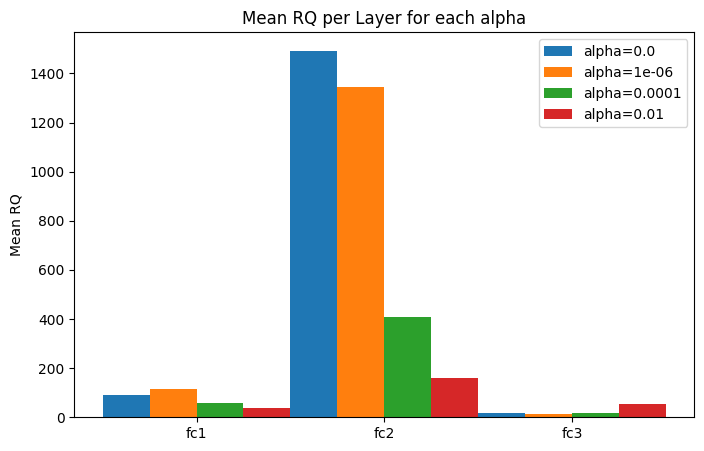

In [12]:
########################################
# EXTRA: Plot Mean RQ per Layer, per Alpha
########################################
import numpy as np

layer_names = ["fc1", "fc2", "fc3"]
num_alphas = len(alphas)
x = np.arange(len(layer_names))  # [0, 1, 2] for the 3 layers
bar_width = 0.25

fig, ax = plt.subplots(figsize=(8, 5))

for i, alpha_val in enumerate(alphas):
    # Compute mean RQ for each layer
    means_per_layer = []
    for layer_name in layer_names:
        rq_values = RQs_by_alpha[alpha_val][layer_name]
        mean_rq = np.mean(rq_values) if len(rq_values) > 0 else 0.0
        means_per_layer.append(mean_rq)

    # Offset for grouped bars
    offset = (i - (num_alphas - 1)/2) * bar_width
    ax.bar(x + offset, means_per_layer, width=bar_width, label=f"alpha={alpha_val}")

ax.set_xticks(x)
ax.set_xticklabels(layer_names)
ax.set_ylabel("Mean RQ")
ax.set_title("Mean RQ per Layer for each alpha")
ax.legend()
plt.show()